# Setup


In [ ]:
# ! pip install pillow
! pip install chromadb
# ! pip install opencv-python onnxruntime
# ! pip install insightface
! pip install FlagEmbedding

# ! pip install tensorflow
# ! pip install deepface
# ! pip install faiss-cpu
# ! pip install faiss-gpu
# ! pip install stanza
# ! pip install sentence-transformers

In [ ]:
import json
import os
import pickle
import shutil
import time
from copy import deepcopy
from difflib import get_close_matches
from io import BytesIO
from pathlib import Path
from typing import Any, Dict, List, Tuple, Union
from urllib.parse import urljoin

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import cv2
import torchvision
import torchvision.transforms as transforms
from insightface.app import FaceAnalysis
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split

from FlagEmbedding import BGEM3FlagModel
from huggingface_hub import login
from peft import LoraConfig, get_peft_model
from sentence_transformers import SentenceTransformer
from transformers import (
    AutoModelForTokenClassification,
    AutoProcessor,
    AutoTokenizer,
    CLIPFeatureExtractor,
    CLIPVisionModel,
    Gemma3ForConditionalGeneration,
    RobertaModel,
    pipeline,
)

import chromadb
from chromadb.config import Settings

import requests
from bs4 import BeautifulSoup
from tqdm import tqdm

In [ ]:
import os
import json
import torch
import chromadb
import requests
import numpy as np
from PIL import Image
from tqdm import tqdm
from io import BytesIO
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from chromadb.config import Settings
from difflib import get_close_matches
from transformers import AutoProcessor, Gemma3ForConditionalGeneration
from transformers import CLIPVisionModel, RobertaModel, AutoTokenizer, CLIPFeatureExtractor

import warnings
warnings.filterwarnings('ignore')

# Configs

In [ ]:
class Config:
    TEXT_EMB_MODEL, TEXT_EMB_PROV = "BAAI/bge-m3", "bge"
    # TEXT_EMB_MODEL, TEXT_EMB_PROV = "jinaai/jina-embeddings-v2-base-en", "jina"
    NER_MODEL = "HooshvareLab/roberta-fa-zwnj-base-ner"

    PROJECT_PATH         = Path("/content/drive/MyDrive/SUT/NLP/Project")
    GT_IMG_DATASET_PATH  = PROJECT_PATH / "face_recognition_ground_truth_images"
    VAL_IMG_DATASET_PATH = PROJECT_PATH / "face_recognition_validation_images"

    CACHE_PATH = PROJECT_PATH / "cached_img_text_embeddings"

    IMG_EMBS_CACHE_PATH  = CACHE_PATH / "img_embeddings.pkl"
    TXT_EMBS_CACHE_PATH  = CACHE_PATH / f"txt_embeddings_{TEXT_EMB_PROV}.pkl"

    GT_IMG_JSON_PATH_1   = GT_IMG_DATASET_PATH / "0000_all_img_link_added_1.json"
    GT_IMG_JSON_PATH_3   = GT_IMG_DATASET_PATH / "0000_all_img_link_added_3.json"
    GT_IMG_JSON_PATH_4   = GT_IMG_DATASET_PATH / "0000_all_img_link_added_4.json"
    GT_IMG_JSON_PATH_7   = GT_IMG_DATASET_PATH / "0000_all_img_link_added_7.json"

# Utilites

In [ ]:
def show_image_with_title(image_path: str, title_text: str = ""):
    try:
        img = Image.open(image_path)
        plt.imshow(img)
        plt.axis('off')
        plt.title(title_text)
        plt.show()
    except FileNotFoundError:
        print(f"Error: Could not display file at '{image_path}'")
    except Exception as e:
        print(f"An error occurred while displaying image: {e}")

In [ ]:
def read_json_file(file_path: str):
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        print(f"Successfully loaded data from {file_path}")
        return data
    except FileNotFoundError:
        print(f"Error: The file at {file_path} was not found.")
        return None
    except json.JSONDecodeError:
        print(f"Error: The file at {file_path} is not a valid JSON file.")
        return None

In [ ]:
def create_people_list(json_data: dict, json_id):
    people_list = []
    for idx, item in enumerate(json_data):
        item_summary = {"iteration": item["iteration"], "json_id": json_id}
        try:
            if type(item["json_pure"]["name"]) is list:
                person_name = " ".join(item["json_pure"]["name"]).replace('\u200c', ' ')
            else:
                person_name = item["json_pure"]["name"].replace('\u200c', ' ')
            item_summary["person_name"] = person_name
        except:
            continue
            item_summary["person_name"] = "unknown"
        people_list.append(item_summary)
    return people_list

In [ ]:
def dict_pretty_print(data_to_print: list | dict):
    formatted_json = json.dumps(
        data_to_print,
        indent=4,
        ensure_ascii=False
    )
    print(formatted_json)

In [ ]:
def get_info_from_dataset(retrieval_result: dict) -> dict:
    json_id = retrieval_result["json_id"]
    iteration = retrieval_result["iteration"]

    if json_id == "json_1":
        data_source = json_1
    elif json_id == "json_3":
        data_source = json_3
    elif json_id == "json_4":
        data_source = json_4

    if data_source[iteration]["iteration"] == iteration:
        return data_source[iteration]
    else:
        for item in data_source:
            if item["iteration"] == iteration:
                return item

In [ ]:
def extract_image_fields(data: Dict[str, Any]) -> Dict[str, List[Dict[str, str]]]:
    extracted_data = [
        {
            "url": image.get("url"),
            "description": image.get("description"),
            "idx": image.get("idx"),
        }
        for image in data.get("image_urls", [])
    ]
    return extracted_data

In [ ]:
from transformers import AutoTokenizer, AutoModelForTokenClassification, pipeline

# Load model and tokenizer
model_name_or_path = "HooshvareLab/roberta-fa-zwnj-base-ner" 
tokenizer = AutoTokenizer.from_pretrained(model_name_or_path)
model = AutoModelForTokenClassification.from_pretrained(model_name_or_path)

# Create NER pipeline
nlp = pipeline("ner", model=model, tokenizer=tokenizer, aggregation_strategy="simple")


def extract_person_names(text):
    global nlp
    # Run NER
    ner_results = nlp(text)
    # Extract PERSON names with start and end indices
    person_entities = []
    for ent in ner_results:
        # print(ent)
        if type(ent) == list:
            ent = ent[0]
        if 'PER' in ent['entity_group']:  # Only person names
            person_entities.append(text[ent["start"]: ent["end"]+1])
    
    return person_entities


pytorch_model.bin:   0%|          | 0.00/471M [00:00<?, ?B/s]

# Text Retrieval Pipeline

### Load data

In [ ]:
with open("/kaggle/input/mashahir-data/merged_3500.json", "r", encoding="utf-8") as f: 
    data = json.load(f)

print(len(data), "records loaded")

3584 records loaded


### Load chroma database if existed before

In [ ]:
import shutil
import chromadb
from chromadb.config import Settings

# Unzip dataset to working directory
shutil.unpack_archive(
    "Mashahir_data/text_chroma_db.zip",
    "/kaggle/working/chroma_scientists_db2"
)

# Load persistent client
client = chromadb.PersistentClient(
    path="/kaggle/working/scientist-data-chroma",
    settings=Settings(allow_reset=True)
)

text_db = client.get_collection("scientists_text")
print("Number of records:", text_db.count())


### Create chroma database if not existed before

In [ ]:
PERSIST_DIR = "/kaggle/working/chroma_scientists_db"
os.makedirs(PERSIST_DIR, exist_ok=True)
client = chromadb.PersistentClient(path=PERSIST_DIR, settings=Settings(allow_reset=True))

text_db  = client.get_or_create_collection(name="scientists_text",  metadata={"hnsw:space": "cosine"})

In [ ]:
from FlagEmbedding import BGEM3FlagModel

# Load model
BGE_m3_model = BGEM3FlagModel('BAAI/bge-m3', use_fp16=True)

# ---- Text Encoder ----
def embed_text(text: str):
    text_embedding = BGE_m3_model.encode(text)['dense_vecs']
    return text_embedding

def upsert_pair(idx, name, text, image_url, t_emb, i_emb):
    meta = {
        "pair_id": idx,
        "name": name,
        "text": text,
        "image_url": image_url if image_url is not None else "",
    }

    if t_emb is not None:
        text_db.add(
            ids=[f"text-{idx}"],
            embeddings=[t_emb.tolist()],
            metadatas=[meta],
        )

In [ ]:
for idx, person in tqdm(enumerate(data)):
    name = person.get("name")
    text = person.get("text_chunk", "").replace("\u200c", "")
    first_sentence = text.split(".")[0]
    t_emb = embed_text(first_sentence)

    image_urls = list(person.get("image", {}).values())
    i_emb = None
    fixed_url = None

    for image_url in image_urls:
        if image_url:
            fixed_url = image_url
            break

    if fixed_url:
        upsert_pair(idx, name, text, fixed_url, t_emb, i_emb)
    # else:
    #     print(name)

### Test Text Retrieval

In [ ]:
def search_by_text(query: str, k=5):
    q_emb = embed_text(query)
    res = text_db.query(query_embeddings=[q_emb.tolist()], n_results=k, include=["metadatas", "distances"])
    return res



In [ ]:
res = search_by_text("مایکل نادری و اسفندیارخان چه ارتباطی با مریم میرزاخانی داشتند؟", k=10)
for meta, dist in zip(res["metadatas"][0], res["distances"][0]):
    print("name:", meta["name"], "score:", 1-dist)
    print("text:", meta["text"])
    print("image:", meta["image_url"], "\n")

name: مریم میرزاخانی score: 0.463573694229126
text: مریم میرزاخانی، ریاضیدان برجسته و استاد دانشگاه معاصر، در ۲۲ اردیبهشت سال ۱۳۵۶ در تهران متولد شد. او در دوران تحصیل خود، دو مدال طلای المپیاد جهانی ریاضی در سالهای ۱۳۷۳ و ۱۳۷۴، به ترتیب در هنگکنگ و کانادا، کسب کرد و در سال ۱۳۸۳ مدرک دکترای خود را از دانشگاه هاروارد زیر نظر کورتیس مکمولن دریافت نمود. میرزاخانی در سال ۱۳۸۷ به عنوان استاد دانشگاه استنفورد مشغول به کار شد و در سال ۱۳۹۳ به دلیل مشارکتهایش در دینامیک و هندسه سطوح ریمانی، مفتخر به دریافت مدال فیلدز گردید. متاسفانه ایشان در تاریخ ۲۳ تیر ۱۳۹۶ در تهران درگذشت.
image: https://articles.unesco.org/sites/default/files/2022-12/COU_01_23_WA_BOX_MARYAM_MARZAKHANI%20%281%29.jpg 

name: امیر نادری score: 0.45444339513778687
text: امیر نادری فیلمساز، نویسنده، کارگردان، عکاس و فیلمنامهنویس ایرانی است. او در تاریخ ۷ خرداد ۱۳۲۴ در آبادان، استان خوزستان متولد شد و به عنوان یکی از چهرههای موج نوی سینمای ایران شناخته میشود.

از آثار او میتوان به فیلمهایی چون «سفری به دنبال هویت» (۱۴۰۰)، «فانوس

In [ ]:
with open("/kaggle/input/text-questions/TextOnly_merged_questions.json", "r", encoding="utf-8") as f:
    questions = json.load(f)

len(questions)

156

In [ ]:
results = []

for q in tqdm(questions):
    query = q["question"] + " - ".join(q["options"])
    res = search_by_text(query, k=5)
    retrieved_data = res["metadatas"][0]
    result = {
        "id": q["id"],
        "question": query,
        "retrieved_data": retrieved_data  
    }
    results.append(result)

with open("/kaggle/working/text_retrieval_output.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

100%|██████████| 156/156 [01:47<00:00,  1.45it/s]


In [ ]:
results[0]

{'id': 'file1_type1_1',
 'question': 'محمد معتضد باهری در چه سالی در شیراز متولد شد؟۱۲۹۰ خورشیدی - ۱۲۹۷ خورشیدی - ۱۳۰۲ خورشیدی - ۱۳۸۶ خورشیدی',
 'retrieved_data': [{'name': 'محمد معتضد باهری',
   'pair_id': 541,
   'image_url': 'https://commons.wikimedia.org/wiki/Special:FilePath/Mohammad_Mo%27tazed-e-Baheri.jpg',
   'text': 'محمد معتضد باهری در سال ۱۲۹۷ خورشیدی در شیراز، استان فارس به دنیا آمد. او در سال ۱۳۸۶ خورشیدی در واشینگتن، دی. سی.، واشینگتن دی. سی. درگذشت. معتضد باهری در دوران محمدرضا پهلوی فعالیت داشت و مشاغلی چون وکالت، وزارت دربار، وزارت دادگستری، ریاست بازرسی کل کشور، دبیری کل حزب رستاخیز و سیاستمداری را بر عهده داشت.'},
  {'pair_id': 2631,
   'name': 'محمدکمال معتضدی',
   'text': 'محمدکمال معتضدی در تاریخ ۲۱ اسفند ۱۳۶۱ در تهران متولد شده است. او در دوره زمانی ۱۳۸۰ تا اکنون فعالیت داشته و در حرفههای صداپیشگی، کمدین و بازیگری مشغول به کار بوده است.\n\nاز جمله آثار صداپیشگی او میتوان به فیلمهای «باباسفنجی: اسفنج بیرون از آب»، «برادران سوپر ماریو»، «رالف خرابکار»، «دانشگاه هیو

### calc hit@k, Percision , Recall

In [ ]:
import json
from tqdm import tqdm
import numpy as np
from pathlib import Path

def calculate_metrics(relevance_labels, k):
    """
    relevance_labels: list of 1 (relevant) or 0 (not relevant), ordered by retriever rank
    k: cutoff rank
    """
    top_k = relevance_labels[:k]
    total_relevant = sum(relevance_labels)

    hit_at_k = 1 if sum(top_k) > 0 else 0
    precision_at_k = sum(top_k) / k
    recall_at_k = sum(top_k) / total_relevant if total_relevant > 0 else 0

    return hit_at_k, precision_at_k, recall_at_k

def check_relevance(question, answer):
  names = extract_person_names(question)
  if any(name in answer for name in names):
        return 1
  else:
        return 0

def evaluate_retriever(json_path, ask_gemini, k_values=[1, 3, 5], save_path=None):
    """
    Evaluate retriever performance on dataset.

    json_path: path to the JSON dataset
    ask_gemini: your function that takes a prompt and returns LLM answer
    k_values: list of K's to evaluate
    save_path: optional path to save results as JSON
    """
    # Load dataset
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Results for each K
    results = {k: {"hit": [], "precision": [], "recall": []} for k in k_values}

    # For per-record storage
    detailed_results = []

    for record in tqdm(data, desc="Evaluating records"):
        question = record["question"]
        retrieved_data = record["retrieved_data"]

        # 1. Determine relevance for each retrieved document
        relevance_labels = []
        for item in retrieved_data:
            retrieved_text = item["text"]
            label = check_relevance(question, retrieved_text)#, ask_gemini
            relevance_labels.append(label)

        # Store per-record relevance labels
        record_metrics = {
            "id": record["id"],
            "question": question,
            "relevance_labels": relevance_labels
        }

        # Skip if there are no relevant documents at all
        if sum(relevance_labels) == 0:
            detailed_results.append(record_metrics)
            continue

        # 2. Calculate metrics for each K
        for k in k_values:
            hit, precision, recall = calculate_metrics(relevance_labels, k)
            results[k]["hit"].append(hit)
            results[k]["precision"].append(precision)
            results[k]["recall"].append(recall)

            # Store per-record metric
            record_metrics[f"Hit@{k}"] = hit
            record_metrics[f"Precision@{k}"] = precision
            record_metrics[f"Recall@{k}"] = recall

        detailed_results.append(record_metrics)

    # 3. Aggregate and prepare final structure
    final_summary = {
        "overall": {},
        "per_record": detailed_results
    }

    for k in k_values:
        avg_hit = np.mean(results[k]["hit"]) if results[k]["hit"] else 0
        avg_precision = np.mean(results[k]["precision"]) if results[k]["precision"] else 0
        avg_recall = np.mean(results[k]["recall"]) if results[k]["recall"] else 0

        final_summary["overall"][f"K={k}"] = {
            "Hit@K": avg_hit,
            "Precision@K": avg_precision,
            "Recall@K": avg_recall
        }

    # 4. Optionally save results to a JSON file
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        with open(save_path, "w", encoding="utf-8") as f:
            json.dump(final_summary, f, ensure_ascii=False, indent=2)
        print(f"\nSaved results to {save_path}")

    # 5. Print summary
    print("\n--- Final Metrics ---")
    for k in k_values:
        metrics = final_summary["overall"][f"K={k}"]
        print(f"\nK = {k}")
        print(f"Hit@{k}: {metrics['Hit@K']:.4f}")
        print(f"Precision@{k}: {metrics['Precision@K']:.4f}")
        print(f"Recall@{k}: {metrics['Recall@K']:.4f}")

    return final_summary

import matplotlib.pyplot as plt

def plot_metrics(results, name):
    ks = [int(k.split("=")[1]) for k in results["overall"].keys()]
    hit = [results["overall"][k]["Hit@K"] for k in results["overall"].keys()]
    precision = [results["overall"][k]["Precision@K"] for k in results["overall"].keys()]
    recall = [results["overall"][k]["Recall@K"] for k in results["overall"].keys()]

    plt.figure(figsize=(8, 5))
    plt.plot(ks, hit, marker="o", label="Hit@K")
    plt.plot(ks, precision, marker="o", label="Precision@K")
    plt.plot(ks, recall, marker="o", label="Recall@K")

    plt.xlabel("K")
    plt.ylabel("Score")
    plt.title(f"{name} Retriever Performance Metrics")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
json_path = "/kaggle/working/text_retrieval_output.json"  
save_path = "/kaggle/working/text_retieval_metrics.json"

metrics = evaluate_retriever(
    json_path=json_path,
    ask_gemini=None,
    k_values=[1, 3, 5],
    save_path=save_path
)


Evaluating records: 100%|██████████| 156/156 [01:13<00:00,  2.11it/s]


Saved results to /kaggle/working/text_retieval_metrics.json

--- Final Metrics ---

K = 1
Hit@1: 0.7738
Precision@1: 0.7738
Recall@1: 0.5958

K = 3
Hit@3: 0.9405
Precision@3: 0.4405
Recall@3: 0.8520

K = 5
Hit@5: 1.0000
Precision@5: 0.3381
Recall@5: 1.0000


TypeError: plot_metrics() missing 1 required positional argument: 'name'

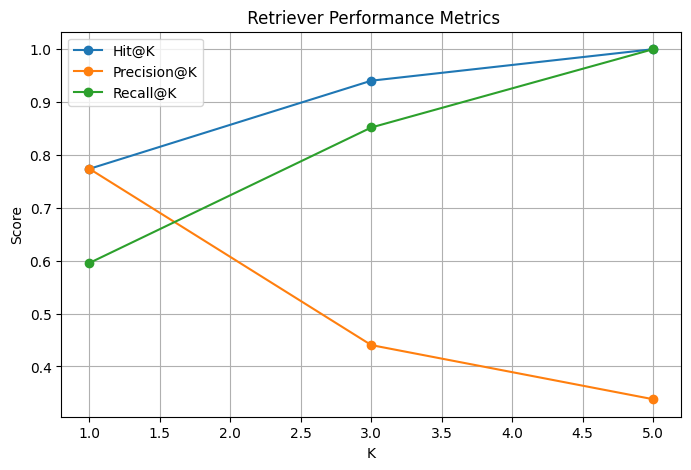

In [ ]:
plot_metrics(results, "")

# Image Retrieval Pipeline

In [ ]:
class FaceRecognizer:
    def __init__(self, model_pack_name: str = 'buffalo_l'):
        self.app = FaceAnalysis(name=model_pack_name, providers=['CPUExecutionProvider'])
        self.app.prepare(ctx_id=0, det_size=(640, 640))

    def get_embedding(self, image_path: Path) -> np.ndarray | None:
        try:
            img = cv2.imread(str(image_path))
            if img is None:
                return None
            faces = self.app.get(img)
            if faces:
                return faces[0].normed_embedding
        except Exception as e:
            print(f"Error processing {image_path}: {e}")
        return None

    def create_database_embeddings(self, GT_IMG_DATASET_PATH: Path) -> Tuple[List[str], List[list]]:
        paths = []
        embeddings = []
        image_files = [p for p in GT_IMG_DATASET_PATH.rglob('*') if p.suffix.lower() in ['.jpg', '.jpeg', '.png']]

        for img_path in tqdm(image_files, desc="Building embedding database"):
            embedding = self.get_embedding(img_path)
            if embedding is not None:
                paths.append(str(img_path))
                embeddings.append(embedding.tolist())
        return paths, embeddings
    
    def get_embeddings_for_paths(self, image_paths: List[Path]) -> Tuple[List[str], List[list]]:
        paths = []
        embeddings = []
        
        for img_path in tqdm(image_paths, desc="Computing embeddings for new images"):
            embedding = self.get_embedding(img_path)
            if embedding is not None:
                paths.append(str(img_path))
                embeddings.append(embedding.tolist())
                
        return paths, embeddings

In [ ]:
class ImageVectorDatabase:
    def __init__(self, collection_name: str = "face_db"):
        self.client = chromadb.Client()
        self.collection = self.client.get_or_create_collection(
            name=collection_name,
            metadata={"hnsw:space": "cosine"}
        )

    def add_batch(self, paths: List[str], embeddings: List[list], batch_size: int = 4000):
        if not embeddings or not paths:
            print("No embeddings or paths provided.")
            return

        num_items = len(paths)

        ids = [f"id_{i}" for i in range(num_items)]
        metadatas = [{"path": path} for path in paths]

        for i in range(0, num_items, batch_size):
            end_index = min(i + batch_size, num_items)

            print(f"Adding batch of {end_index - i} items to the vector database...")

            batch_embeddings = embeddings[i:end_index]
            batch_metadatas = metadatas[i:end_index]
            batch_ids = ids[i:end_index]

            self.collection.add(
                embeddings=batch_embeddings,
                metadatas=batch_metadatas,
                ids=batch_ids
            )

        print(f"Successfully added {num_items} total items to the collection.")

    def search(self, query_embedding: np.ndarray, k: int = 1):
        return self.collection.query(
            query_embeddings=[query_embedding.tolist()],
            n_results=k
        )

In [ ]:
def init_image_pipeline():
    print("Initializing Face Recognizer...")
    recognizer = FaceRecognizer()
    
    Config.CACHE_PATH.mkdir(exist_ok=True)
    
    paths = []
    embeddings = []

    if Config.IMG_EMBS_CACHE_PATH.exists():
        print(f"Loading cached embeddings from {Config.IMG_EMBS_CACHE_PATH}...")
        with open(Config.IMG_EMBS_CACHE_PATH, 'rb') as f:
            data = pickle.load(f)
            paths, embeddings = data["paths"], data["embeddings"]

        cached_paths_set = set(paths)
        all_image_files = [str(p) for p in Config.GT_IMG_DATASET_PATH.rglob('*') if p.suffix.lower() in ['.jpg', '.jpeg', '.png']]
        new_image_paths = [Path(p) for p in all_image_files if p not in cached_paths_set]

        if new_image_paths:
            print(f"Found {len(new_image_paths)} new images to process.")
            new_paths, new_embeddings = recognizer.get_embeddings_for_paths(new_image_paths)
            
            paths.extend(new_paths)
            embeddings.extend(new_embeddings)
            
            print(f"Updating cache file at {Config.IMG_EMBS_CACHE_PATH}...")
            with open(Config.IMG_EMBS_CACHE_PATH, 'wb') as f:
                pickle.dump({"paths": paths, "embeddings": embeddings}, f)
            print("Cache updated successfully.")
        else:
            print("Cache is up to date. No new images found.")

    else:
        print(f"Cache not found. Building embeddings from scratch for all images in {Config.GT_IMG_DATASET_PATH}...")
        paths, embeddings = recognizer.create_database_embeddings(Config.GT_IMG_DATASET_PATH)
        
        if paths:
            with open(Config.IMG_EMBS_CACHE_PATH, 'wb') as f:
                pickle.dump({"paths": paths, "embeddings": embeddings}, f)
            print(f"Embeddings cached to {Config.IMG_EMBS_CACHE_PATH}")

    if not embeddings:
        print("No embeddings found in the database. Exiting.")
        exit()

    print("Initializing Vector Database...")
    vector_db = ImageVectorDatabase(collection_name="insightface_faces")
    vector_db.add_batch(paths, embeddings)
    print(f"Vector database ready with {vector_db.collection.count()} entries.")
    
    return recognizer, vector_db

In [ ]:
def search_person_by_image(
        query_image_path: Path,
        n_results: int,
        recognizer: FaceRecognizer,
        vector_db: ImageVectorDatabase,
    ) -> list | None:
    query_embedding = recognizer.get_embedding(query_image_path)
    if query_embedding is None:
        print(f"Could not get embedding for {query_image_path}. No face found or image is invalid.")
        return None

    results = vector_db.search(query_embedding, k=n_results)

    if not results or not results['ids'][0]:
        print("No matches found in the database for this person.")
        return None

    best_matches = results['metadatas'][0]
    distances = results['distances'][0]

    search_results = []
    for idx, (metadata, distance) in enumerate(zip(best_matches, distances)):
        json_id = "json_" + metadata["path"].split("/")[-3].split("_")[-1]
        iteration = int(metadata["path"].split("/")[-2])
        person_info = get_info_from_dataset(json_id, iteration)

        item = {
            "nth_match": idx + 1,
            "json_id": json_id,
            "iteration": iteration,
            "person_name": person_info["json_pure"]["name"],
            "distance": distance,
            # "json": person_info["json_refined"],
            "textual_content": person_info["textual_content_response"],
            # "question_and_answer": person_info["question_and_answer_response"],
            "image_data": extract_image_fields(person_info["image_data"]),
            "match_image_path": metadata["path"],
        }
        search_results.append(item)
    return search_results

In [ ]:
def val_image_pipeline():
    recognizer, vector_db = init_image_pipeline()
    validation_imgs = os.listdir(Config.VAL_IMG_DATASET_PATH)
    for val_img_name in validation_imgs:
        start_time = time.time()
        img_path = Config.VAL_IMG_DATASET_PATH / val_img_name
        print("*" * 50 + f" Processing {val_img_name} " + "*" * 50)

        query_embedding = recognizer.get_embedding(img_path)

        if query_embedding is None:
            print(f"Could not get embedding for {img_path}")
            continue

        results = vector_db.search(query_embedding)

        best_match_distance = results['distances'][0][0]
        proposed_img_path = results['metadatas'][0][0]['path']

        print(f"Best match found: {proposed_img_path}")
        print(f"Cosine Distance: {best_match_distance:.4f}")

        show_image_with_title(str(img_path), f"Query Image: {val_img_name}")
        show_image_with_title(proposed_img_path, f"Proposed Match | Distance: {best_match_distance:.4f}")

        taken_time = time.time() - start_time
        print(f"Time taken: {taken_time:.3f} seconds")
        print("#" * 120)


val_image_pipeline()

# Merging Data Sources

In [ ]:
json_1 = read_json_file(Config.GT_IMG_JSON_PATH_1)
json_3 = read_json_file(Config.GT_IMG_JSON_PATH_3)
json_4 = read_json_file(Config.GT_IMG_JSON_PATH_4)
json_7 = read_json_file(Config.GT_IMG_JSON_PATH_7)

json_1_people_list = create_people_list(json_1, "json_1")
json_3_people_list = create_people_list(json_3, "json_3")
json_4_people_list = create_people_list(json_4, "json_4")
json_7_people_list = create_people_list(json_7, "json_7")


people_list_total = [*json_1_people_list,
                     *json_3_people_list,
                     *json_4_people_list,
                     *json_7_people_list]

Successfully loaded data from /content/drive/MyDrive/SUT/NLP/Project/face_recognition_ground_truth_images/0000_all_img_link_added_1.json
Successfully loaded data from /content/drive/MyDrive/SUT/NLP/Project/face_recognition_ground_truth_images/0000_all_img_link_added_3.json
Successfully loaded data from /content/drive/MyDrive/SUT/NLP/Project/face_recognition_ground_truth_images/0000_all_img_link_added_4.json
Successfully loaded data from /content/drive/MyDrive/SUT/NLP/Project/face_recognition_ground_truth_images/0000_all_img_link_added_7.json


# Initializing Text & Image Retrieval Pipelines

In [ ]:
text_embedder, text_vector_db = init_text_pipeline(people_list_total)

Initializing Text Embedder...
Initializing embedder with provider: 'bge' and model: 'BAAI/bge-m3'...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/444 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

... (26 outputs left out)

pre tokenize: 100%|██████████| 2/2 [00:00<00:00, 34.55it/s]
You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
Inference Embeddings: 100%|██████████| 2/2 [01:23<00:00, 41.70s/it]


Cache updated with new embeddings at /content/drive/MyDrive/SUT/NLP/Project/face_recognition_ground_truth_images/txt_embeddings_bge.pkl
Initializing Vector Database for text...


Adding to Vector DB: 100%|██████████| 4/4 [00:03<00:00,  1.07it/s]

Successfully added 3562 total items to the collection 'bge_person_names'.
Text vector database ready with 3562 entries.


In [ ]:
face_recognizer, image_vector_db = init_image_pipeline()

Initializing Face Recognizer...
download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:04<00:00, 69598.21KB/s]


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)
Loading cach

In [ ]:
person_name_extractor = PersonNameExtractor()

# Testing Integrated Multimodal RAG

## Text as a Query

In [ ]:
sample_text = """
هومن سیدی بازیگر و کارگردان تئاتر و سینما و تلویزیون ۴۵ ساله اهل رشت بوده
 و از سال ۱۳۷۳ تا به حال در عرصه کارگردانی و بازیگری فعالیت می‌کند 
 سریال وحشی و قورباغه و فیلم‌های مغزهای کوچک زنگ زده، خشم و هیاهو
  ، آفریقا و سیزده از آثار هومن سیدی می‌باشند
"""

text_retrieval_result = search_person_by_text(
    sample_text, 
    1,
    person_name_extractor, 
    text_embedder, 
    text_vector_db, 
)
dict_pretty_print(text_retrieval_result)

{
    "json_id": "json_3",
    "iteration": 20,
    "person_name": "هومن سیدی",
    "distance": 4.172325134277344e-07,
    "taken_time": 15.298111200332642
}
{
    "iteration": 20,
    "json_pure": {
        "name": "هومن سیدی",
        "sex": "مرد",
        "nick-names": [],
        "birth": {
            "date": {
                "year": 1359,
                "month": 9,
                "day": 8
            },
            "location": {
                "province": "گیلان",
                "city": "رشت",
                "coordinates": {
                    "latitude": null,
                    "longitude": null
                }
            }
        },
        "death": null,
        "era": "دهه هشتاد - اکنون",
        "occupation": [
            "بازیگر",
            "کارگردان",
            "فیلم‌نامه‌نویس",
            "تدوین‌گر"
        ],
        "works": [
            {
                "title": "یک تکه نان",
                "type": "فیلم",
                "release_date": {
       

## Image as a Query

In [ ]:
sample_image_path = Config.PROJECT_PATH / "homan_seyedi.jpg"
image_retrieval_result = search_person_by_image(
    sample_image_path, 
    1,
    face_recognizer, 
    image_vector_db, 
)
dict_pretty_print(image_retrieval_result)

{
    "iteration": 20,
    "json_id": "json_3",
    "match_image_path": "/content/drive/MyDrive/SUT/NLP/Project/face_recognition_ground_truth_images/downloaded_images_filter_3/20/003.jpeg",
    "distance": 0.0,
    "taken_time": 1.1749625205993652
}
{
    "iteration": 20,
    "json_pure": {
        "name": "هومن سیدی",
        "sex": "مرد",
        "nick-names": [],
        "birth": {
            "date": {
                "year": 1359,
                "month": 9,
                "day": 8
            },
            "location": {
                "province": "گیلان",
                "city": "رشت",
                "coordinates": {
                    "latitude": null,
                    "longitude": null
                }
            }
        },
        "death": null,
        "era": "دهه هشتاد - اکنون",
        "occupation": [
            "بازیگر",
            "کارگردان",
            "فیلم‌نامه‌نویس",
            "تدوین‌گر"
        ],
        "works": [
            {
                "tit

## Final Function

In [ ]:
from Main_pipeline.ipynb.call_generative_model  import call_generative_model

ans = call_generative_model(
        input_text="سلامممم",
        input_image_path=None,
        model_name="gemini-2.5-flash"
    )
ans

'سلام! چطوری؟ 😊'

In [ ]:
def RAG(query, image_url=None):

    # retrieved_texts = search_by_text(query=query, k=3)["metadatas"][0]
    text_retrieve_result = search_person_by_text(
        query, 
        1, 
        person_name_extractor, 
        text_embedder, 
        text_vector_db
    )

    if text_retrieve_result:
        retrieved_texts = text_retrieve_result[0]["textual_content"]
    else: 
        retrieved_texts = None


    if image_url:
        image_retrieve_result = search_person_by_image(
            image_url, 
            1,
            face_recognizer, 
            image_vector_db
        )
        retrieved_images_paths = [image_retrieve_result[0]["match_image_path"]]
        if not retrieved_texts:
            retrieved_texts = image_retrieve_result[0]["textual_content"]
    else:
        retrieved_images_paths = None

    ans = call_generative_model(
        input_text=query,
        input_image_path=image_url,
        retrieved_texts=retrieved_texts,
        retrieved_images_paths=retrieved_images_paths,
        model_name="gemini-2.5-flash"
    )

    return ans

In [ ]:
sample_text = """
هومن سیدی کیست؟
"""

RAG(sample_text)

In [ ]:
sample_text = """
تصویر داده شده مربوط به چه فردی است؟
"""

sample_image_path = str(Config.PROJECT_PATH / "homan_seyedi.jpg")

RAG(sample_text, sample_image_path)